In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv(Path.cwd().parent / ".env")

url = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)
engine = create_engine(url)

In [2]:
clientes = pd.read_sql("SELECT * FROM clientes", engine)
produtos = pd.read_sql("SELECT * FROM produtos", engine)
pedidos  = pd.read_sql("SELECT * FROM pedidos", engine)
itens    = pd.read_sql("SELECT * FROM itens_pedido", engine)

In [3]:
pedidos["data_pedido"] = pd.to_datetime(pedidos["data_pedido"])
clientes["data_cadastro"] = pd.to_datetime(clientes["data_cadastro"])

itens["valor_item"] = itens["quantidade"] * itens["preco_unitario"]
itens["valor_item"] = itens["valor_item"].astype(float)

In [4]:
base = (
    itens
    .merge(pedidos, on="id_pedido")
    .merge(produtos[["id_produto", "nome", "categoria"]], on="id_produto")
    .merge(clientes[["id_cliente", "nome", "estado"]], on="id_cliente",
           suffixes=("_produto", "_cliente"))
)

vendas = base[base["status"] != "cancelado"].copy()
print(base.shape, vendas.shape)

(7562, 13) (7040, 13)


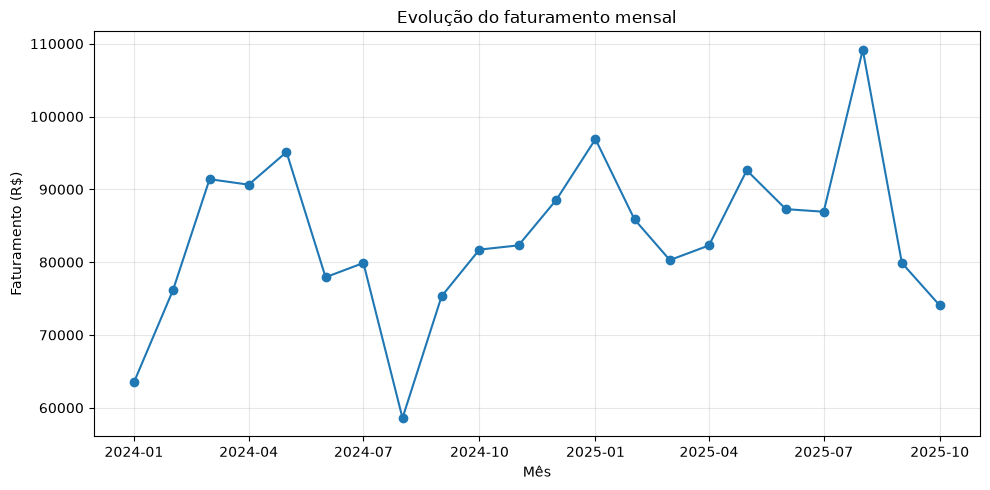

In [5]:
por_mes = (
    vendas.groupby(vendas["data_pedido"].dt.to_period("M"))["valor_item"]
    .sum()
)
por_mes.index = por_mes.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(por_mes.index, por_mes.values, marker="o")
ax.set_title("Evolução do faturamento mensal")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento (R$)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/img/faturamento_mensal.png", dpi=150)
plt.show()

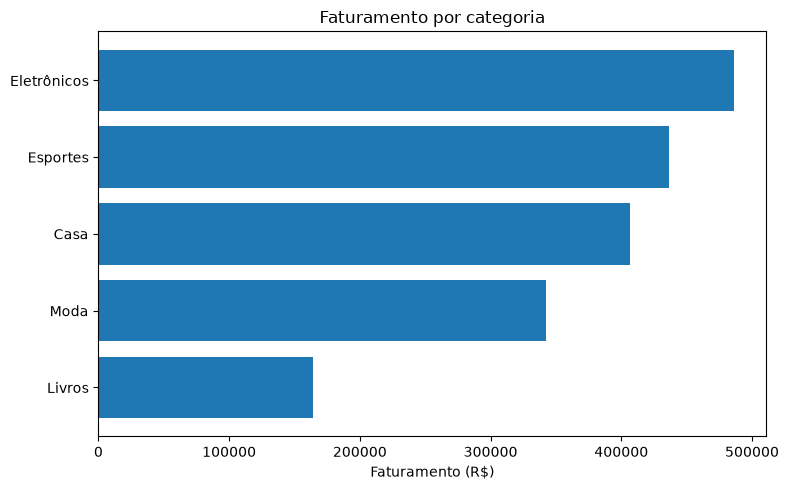

In [6]:
por_categoria = (
    vendas.groupby("categoria")["valor_item"].sum()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(por_categoria.index, por_categoria.values)
ax.set_title("Faturamento por categoria")
ax.set_xlabel("Faturamento (R$)")
plt.tight_layout()
plt.savefig("../docs/img/faturamento_categoria.png", dpi=150)
plt.show()

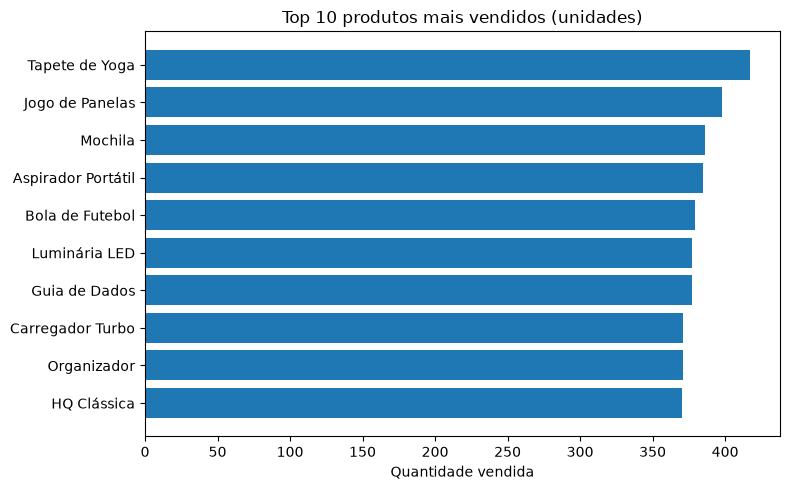

In [7]:
top10 = (
    vendas.groupby("nome_produto")["quantidade"].sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10.values)
ax.set_title("Top 10 produtos mais vendidos (unidades)")
ax.set_xlabel("Quantidade vendida")
plt.tight_layout()
plt.savefig("../docs/img/top_produtos.png", dpi=150)
plt.show()

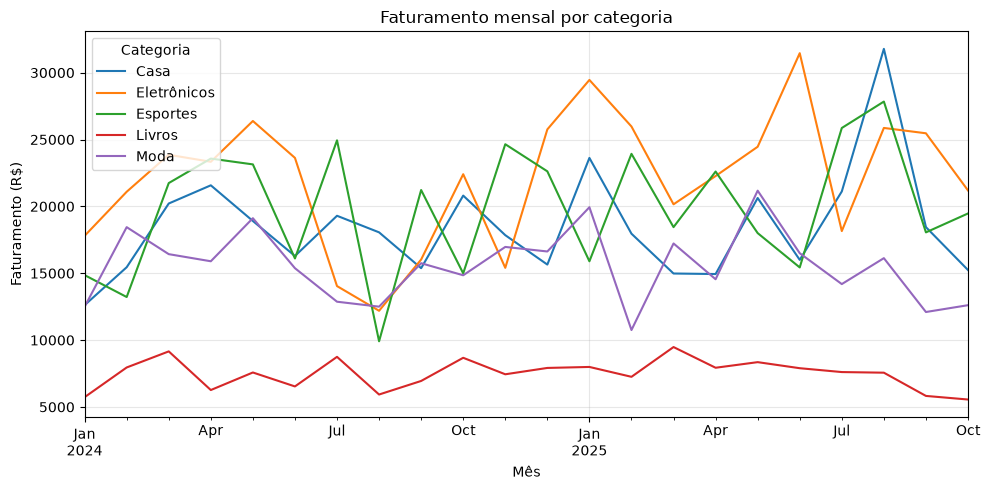

In [8]:
cat_mes = (
    vendas.groupby([vendas["data_pedido"].dt.to_period("M"), "categoria"])["valor_item"]
    .sum()
    .unstack()
)
cat_mes.index = cat_mes.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 5))
cat_mes.plot(ax=ax)
ax.set_title("Faturamento mensal por categoria")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento (R$)")
ax.legend(title="Categoria")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../docs/img/categoria_ao_longo_do_tempo.png", dpi=150)
plt.show()